In [21]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# machine Learning

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
#from sklearn.file import joblib

In [34]:
df = pd.read_csv('housing.csv')
df.head()

,RM,LSTAT,PTRATIO,MEDV
0,6.575,4.98,15.3,504000.0
1,6.421,9.14,17.8,453600.0
2,7.185,4.03,17.8,728700.0
3,6.998,2.94,18.7,701400.0
4,7.147,5.33,18.7,760200.0


In [35]:
df.tail()

,RM,LSTAT,PTRATIO,MEDV
484,6.593,9.67,21.0,470400.0
485,6.120,9.08,21.0,432600.0
486,6.976,5.64,21.0,501900.0
487,6.794,6.48,21.0,462000.0
488,6.030,7.88,21.0,249900.0


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 489 entries, 0 to 488
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   RM       489 non-null    float64
 1   LSTAT    489 non-null    float64
 2   PTRATIO  489 non-null    float64
 3   MEDV     489 non-null    float64
dtypes: float64(4)
memory usage: 15.4 KB


In [37]:
df.isnull().sum()

RM         0
LSTAT      0
PTRATIO    0
MEDV       0
dtype: int64

In [38]:
df.describe()

,RM,LSTAT,PTRATIO,MEDV
count,489.000000,489.000000,489.000000,4.890000e+02
mean,6.240288,12.939632,18.516564,4.543429e+05
std,0.643650,7.081990,2.111268,1.653403e+05
min,3.561000,1.980000,12.600000,1.050000e+05
25%,5.880000,7.370000,17.400000,3.507000e+05
50%,6.185000,11.690000,19.100000,4.389000e+05
75%,6.575000,17.120000,20.200000,5.187000e+05
max,8.398000,37.970000,22.000000,1.024800e+06


In [39]:
print(f'see the missing values:: {df.isnull().sum}')

see the missing values:: <bound method DataFrame.sum of         RM  LSTAT  PTRATIO   MEDV
0    False  False    False  False
1    False  False    False  False
2    False  False    False  False
3    False  False    False  False
4    False  False    False  False
..     ...    ...      ...    ...
484  False  False    False  False
485  False  False    False  False
486  False  False    False  False
487  False  False    False  False
488  False  False    False  False

[489 rows x 4 columns]>


In [40]:
from sklearn.preprocessing import StandardScaler
X = df.drop('RM', axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print(X_scaled_df)

        LSTAT   PTRATIO      MEDV
0   -1.125077 -1.525083  0.300640
1   -0.537070 -0.339748 -0.004498
2   -1.259357 -0.339748  1.661047
3   -1.413427  0.086973  1.495764
4   -1.075605  0.086973  1.851759
..        ...       ...       ...
484 -0.462155  1.177482  0.097215
485 -0.545551  1.177482 -0.131639
486 -1.031787  1.177482  0.287926
487 -0.913055  1.177482  0.046358
488 -0.715168  1.177482 -1.237764

[489 rows x 3 columns]


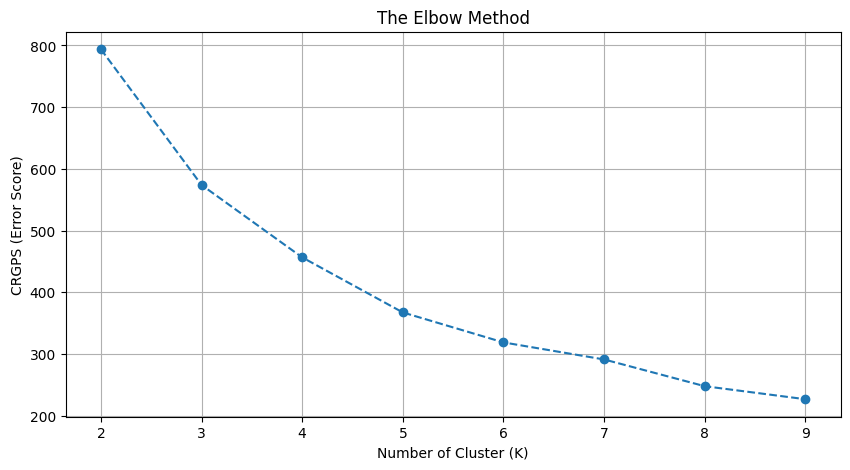

In [43]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

cgrps = []

for i in range(2, 10):
    Kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    Kmeans.fit(X_scaled)
    cgrps.append(Kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(2, 10), cgrps, marker='o', linestyle='--')
plt.title("The Elbow Method")
plt.xlabel('Number of Cluster (K)')
plt.ylabel('CRGPS (Error Score)')
plt.grid(True)
plt.show()

In [44]:
# Initiate Kmeans with n_clusters.abs

Kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)

clusters = Kmeans.fit_predict(X_scaled)

df["cluster_group"] = clusters

df[['RM', 'cluster_group']].head()

,RM,cluster_group
0,6.575,0
1,6.421,7
2,7.185,6
3,6.998,6
4,7.147,6


In [45]:
# Analyzing the clusters

cluster_analysis = df.drop('RM', axis=1).groupby('cluster_group').mean()

important_columns = ['LSTAT', 'PTRATIO', 'MEDV']

print(cluster_analysis[important_columns])

                   LSTAT    PTRATIO           MEDV
cluster_group                                     
0               6.741176  14.626471  623205.882353
1              15.918976  20.244094  362010.236220
2               8.434878  19.730488  481565.853659
3              25.923333  20.158333  234955.000000
4              26.667778  14.811111  312433.333333
5              13.471923  15.019231  419919.230769
6               5.330213  17.897872  687236.170213
7              10.511023  17.580682  462047.727273
8               3.983750  15.425000  920850.000000


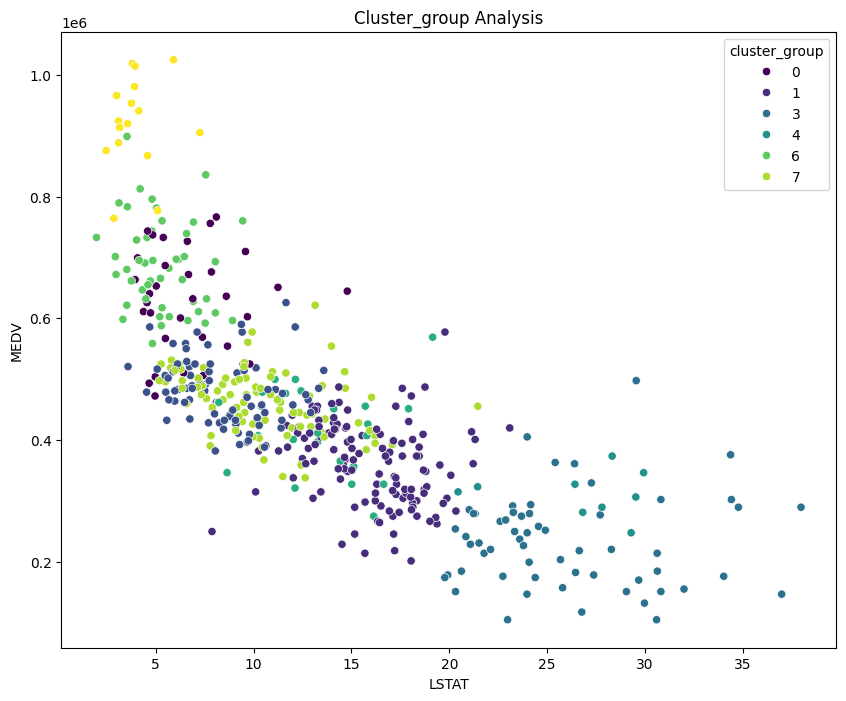

In [47]:
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.scatterplot(data=df, x='LSTAT', y='MEDV', hue='cluster_group', palette='viridis')
plt.title('Cluster_group Analysis')
plt.show()